# Pertemuan 6 — Model ARIMA dan SARIMA: Identifikasi Orde
## Notebook Praktikum · Analisis Runtun Waktu (SDT-3329)

**Program Studi Sains Data · Fakultas Digital, Desain dan Bisnis · Institut Teknologi Sains Bandung**
Semester 6 · 3 SKS (T: 2, P: 1) · Mata kuliah syarat: Statistika Komputasi, Pemrograman Statistika, Aljabar Linear ·
Dosen pengampu: Bakti Siregar, S.Si., M.Sc

---

### Keselarasan dengan RPS (OBE)

| Komponen | Isi |
|---|---|
| **Kemampuan akhir (Sub-CPMK)** | Mahasiswa mampu mengidentifikasi parameter model ARIMA (p,d,q) dan SARIMA untuk data runtun waktu. |
| **CPL / CPMK** | CPL-1 · CPL-3 · CPMK-3 |
| **Indikator** | Mampu menggunakan plot ACF/PACF dan kriteria informasi (AIC/BIC) untuk menentukan orde p, d, q pada model ARIMA/SARIMA. |
| **Kriteria penilaian** | Ketepatan identifikasi orde model. |
| **Materi pembelajaran** | Konsep AR, MA, ARMA; differencing untuk stasioneritas; identifikasi orde dari ACF/PACF; model SARIMA. |
| **Konsep pemrograman** | Otomasi pencarian orde: `itertools.product`, penanganan galat dan peringatan estimasi yang gagal (bagian 🧠) |
| **Bobot penilaian minggu ini** | 4% |
| **Alokasi waktu** | TM 2 × 50′ · Praktikum 1 × 170′ · PT 2 × 60′ · BM 2 × 60′ |
| **Keterkaitan tugas (RTM)** | — (bekal Tugas 2: identifikasi ARIMA) |
| **Pustaka** | Hyndman & Athanasopoulos (2021) Bab 9.1–9.9; Box dkk. (2015) Bab 6 |

**Dataset:** Pertumbuhan PDB riil AS kuartalan · Sunspots tahunan 1700–2008 · Airline Passengers · deret simulasi ARMA
**Pustaka Python:** pandas · NumPy · Matplotlib · seaborn · statsmodels

### Alur kerja Box–Jenkins yang diikuti notebook ini

```
1 Visualisasi → 2 Uji stasioneritas → 3 Differencing → 4 ACF & PACF
      → 5 Kandidat orde AR/MA → 6 Estimasi parameter → 7 Bandingkan & evaluasi model
```

### Peta notebook

| Bagian | Langkah | Isi | Indikator RPS |
|---|---|---|---|
| 1 | Visualisasi data | Plot deret asli: tren, musiman, siklus, perubahan variansi; kebutuhan transformasi log | — |
| 2 | Memeriksa stasioneritas | Statistik bergulir, uji ADF dan KPSS pada level | Differencing untuk stasioneritas |
| 3 | Differencing | Menentukan d (dan D musiman) terkecil; memeriksa ulang hasil differencing | Differencing untuk stasioneritas |
| 4 | Grafik ACF dan PACF | Membaca ACF/PACF deret yang sudah stasioner (lag biasa dan lag musiman) | **Identifikasi orde dari ACF/PACF** |
| 5 | Kandidat orde AR dan MA | Persamaan AR, MA, ARMA, SARIMA; aturan pola ACF/PACF; daftar kandidat | **Identifikasi orde p, d, q** |
| 6 | Estimasi parameter | Mengestimasi kandidat; syarat stasioner & invertibel dari akar polinomial | Konsep dasar AR, MA, ARMA |
| 7 | Membandingkan & mengevaluasi | AIC/AICc/BIC, pencarian orde, uji residu Ljung–Box, uji pada orde yang diketahui | **Menggunakan AIC/BIC** · Ketepatan identifikasi |
| 8 | 🧠 Konsep pemrograman | Pencarian orde otomatis yang tangguh (`itertools`, exception, peringatan) | — |
| 9–10 | Latihan, ringkasan, logbook | — | — |

### Cara menggunakan notebook ini

- Jalankan sel berurutan (Google Colab atau Jupyter lokal). Di Colab, `statsmodels` sudah tersedia.
- Sel **LATIHAN** berisi `TODO`; lengkapi selama praktikum. Bagian 🧠 **Konsep Pemrograman** menjelaskan prinsip di balik kode,
  bukan sekadar cara memanggil pustaka.
- Penilaian memakai rubrik RPS — *Kualitas Implementasi (Kode & Model)* dan *Interpretasi & Visualisasi Hasil* — serta
  Rubrik PRAKTIKUM (eksekusi 40%, pembersihan data 35%, penanganan error & modularitas 25%).
- Unggah notebook dan logbook ke LMS/Virtual Lab setelah praktikum.

---
## 0. Persiapan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, itertools, time

import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'figure.figsize': (10, 3.4)})
pd.set_option('display.width', 140)
RANDOM_STATE = 42

# Airline Passengers (bulanan, 1949–1960)
air = pd.read_csv('https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv',
                  parse_dates=['Month'], index_col='Month')['Passengers'].asfreq('MS')
# PDB riil AS (kuartalan, 1959–2009) dan pertumbuhannya (% per kuartal)
mac = sm.datasets.macrodata.load_pandas().data
mac.index = pd.period_range('1959Q1', periods=len(mac), freq='Q').to_timestamp(); mac = mac.asfreq('QS')
log_gdp = np.log(mac.realgdp).rename('log PDB riil')
gdp_g = (log_gdp.diff() * 100).dropna().rename('pertumbuhan')
# Sunspots (tahunan, 1700–2008)
sunth = sm.datasets.sunspots.load_pandas().data
sunth = pd.Series(sunth.SUNACTIVITY.values, index=pd.date_range('1700', periods=len(sunth), freq='YS'), name='sunspots')

print(f'Airline: {len(air)} bulan | PDB: {len(log_gdp)} kuartal | Sunspots: {len(sunth)} tahun')

Airline: 144 bulan | PDB: 203 kuartal | Sunspots: 309 tahun


---
## 1. Visualisasi Data Time Series

Langkah pertama selalu **melihat data**. Dari plot deret asli kita mencari:

| Yang dicari | Konsekuensi untuk model |
|---|---|
| **Tren** (rata-rata naik/turun) | Deret tidak stasioner dalam rata-rata → kemungkinan perlu differencing biasa (d) |
| **Musiman** (pola berulang tiap m periode) | Perlu komponen musiman (P, D, Q)ₘ |
| **Variansi yang membesar** seiring level | Transformasi log/Box–Cox sebelum differencing |
| **Siklus** tanpa periode tetap | Biasanya ditangkap komponen AR, bukan differencing |
| Pencilan, perubahan struktural | Perlu penanganan khusus sebelum identifikasi |

In [4]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=[
        'Log PDB Riil AS (Kuartalan)',
        'Pertumbuhan PDB Riil (% per Kuartal)',
        'Sunspots Tahunan (1700–2008)',
        'Airline Passengers'
    ],
    specs=[
        [{'secondary_y': False}, {'secondary_y': False}],
        [{'secondary_y': False}, {'secondary_y': True}]
    ],
    vertical_spacing=0.13,
    horizontal_spacing=0.10
)

# 1. Log PDB riil AS
fig.add_trace(
    go.Scatter(
        x=log_gdp.index,
        y=log_gdp.values,
        mode='lines',
        name='Log GDP',
        line=dict(width=1.2)
    ),
    row=1, col=1
)

# 2. Pertumbuhan PDB riil
fig.add_trace(
    go.Scatter(
        x=gdp_g.index,
        y=gdp_g.values,
        mode='lines',
        name='GDP Growth',
        line=dict(width=1.2)
    ),
    row=1, col=2
)

fig.add_hline(
    y=gdp_g.mean(),
    line_dash='dash',
    line_width=1,
    line_color='red',
    annotation_text=f'Mean = {gdp_g.mean():.2f}',
    row=1, col=2
)

# 3. Sunspots
fig.add_trace(
    go.Scatter(
        x=sunth.index,
        y=sunth.values,
        mode='lines',
        name='Sunspots',
        line=dict(width=1.2)
    ),
    row=2, col=1
)

# 4. Airline Passengers
fig.add_trace(
    go.Scatter(
        x=air.index,
        y=air.values,
        mode='lines',
        name='Passengers',
        line=dict(width=1.2)
    ),
    row=2, col=2,
    secondary_y=False
)

fig.add_trace(
    go.Scatter(
        x=air.index,
        y=np.log(air.values),
        mode='lines',
        name='Log Passengers',
        line=dict(width=1.2, dash='dash')
    ),
    row=2, col=2,
    secondary_y=True
)

# Label sumbu
fig.update_xaxes(title_text='Tahun', row=1, col=1)
fig.update_xaxes(title_text='Tahun', row=1, col=2)
fig.update_xaxes(title_text='Tahun', row=2, col=1)
fig.update_xaxes(title_text='Tahun', row=2, col=2)

fig.update_yaxes(title_text='Log GDP', row=1, col=1)
fig.update_yaxes(title_text='Pertumbuhan (%)', row=1, col=2)
fig.update_yaxes(title_text='Aktivitas Sunspots', row=2, col=1)
fig.update_yaxes(title_text='Jumlah Penumpang', row=2, col=2, secondary_y=False)
fig.update_yaxes(title_text='Log Penumpang', row=2, col=2, secondary_y=True)

# Layout
fig.update_layout(
    title=dict(
        text='Visualisasi Dataset Time Series',
        x=0.5,
        xanchor='center'
    ),
    height=700,
    template='plotly_white',
    hovermode='x unified',
    legend=dict(
        orientation='h',
        y=-0.12,
        x=0.5,
        xanchor='center'
    )
)

fig.show()

In [5]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Menghitung rentang musiman setiap tahun
rentang = pd.DataFrame({
    'Rentang Asli': air.groupby(air.index.year).agg(lambda s: s.max() - s.min()),
    'Rentang Log': np.log(air).groupby(air.index.year).agg(lambda s: s.max() - s.min())
})

# Menampilkan tabel
display(rentang.round(3))

# Menghitung rasio rentang tahun terakhir terhadap tahun pertama
rasio_asli = rentang.iloc[-1, 0] / rentang.iloc[0, 0]
rasio_log = rentang.iloc[-1, 1] / rentang.iloc[0, 1]

print(
    f"Rasio rentang {rentang.index[-1]}/{rentang.index[0]} — "
    f"Asli: {rasio_asli:.1f}× | Log: {rasio_log:.1f}×"
)

# Visualisasi Plotly
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=[
        'Rentang Musiman Data Asli',
        'Rentang Musiman Setelah Transformasi Log'
    ]
)

fig.add_trace(
    go.Scatter(
        x=rentang.index,
        y=rentang['Rentang Asli'],
        mode='lines+markers',
        name='Rentang Asli',
        hovertemplate='Tahun: %{x}<br>Rentang: %{y:.2f}<extra></extra>'
    ),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(
        x=rentang.index,
        y=rentang['Rentang Log'],
        mode='lines+markers',
        name='Rentang Log',
        hovertemplate='Tahun: %{x}<br>Rentang Log: %{y:.3f}<extra></extra>'
    ),
    row=1, col=2
)

fig.update_xaxes(title_text='Tahun')
fig.update_yaxes(title_text='Rentang Penumpang (ribu)', row=1, col=1)
fig.update_yaxes(title_text='Rentang Log', row=1, col=2)

fig.update_layout(
    title='Perbandingan Rentang Musiman Airline Passengers',
    title_x=0.5,
    template='plotly_white',
    height=450,
    hovermode='x unified',
    showlegend=False
)

fig.show()

,Rentang Asli,Rentang Log
Month,,
1949,44,0.353
1950,56,0.400
1951,54,0.317
1952,71,0.347
1953,92,0.413
1954,114,0.474
1955,131,0.446
1956,142,0.421
1957,166,0.439


Rasio rentang 1960/1949 — Asli: 5.3× | Log: 1.3×


> **Bacaan Plot:**
>
> - **Log PDB riil AS** menunjukkan tren naik yang jelas sehingga mengindikasikan data tidak stasioner. Sebaliknya, **pertumbuhan PDB riil** (selisih log × 100) berfluktuasi di sekitar rata-rata yang relatif konstan sehingga menjadi kandidat deret stasioner.
>
> - **Sunspots** menunjukkan pola siklus sekitar 11 tahun di sekitar level yang relatif tetap, tanpa tren jangka panjang yang jelas. Pola siklusnya tidak simetris: kenaikan aktivitas cenderung lebih cepat dibandingkan penurunannya.
>
> - **Airline Passengers** menunjukkan tren naik sekaligus pola musiman 12 bulanan dengan amplitudo yang semakin besar. Rentang musiman pada data asli meningkat seiring kenaikan level data, sedangkan setelah transformasi log rentangnya relatif lebih stabil. Oleh karena itu, **log Airline Passengers** menjadi kandidat yang lebih sesuai untuk pemodelan.
>
> **Kesimpulan:** Visualisasi memberikan hipotesis awal mengenai karakteristik masing-masing deret, khususnya tren, pola musiman, dan kestabilan variansi. Hipotesis tersebut akan diuji secara formal pada Langkah 2.

---
## 2. Memeriksa Stasioneritas Data

Deret **stasioner (lemah)** memiliki rata-rata dan variansi yang konstan serta autokovarians yang hanya bergantung pada jarak lag.
Model ARMA mensyaratkan deret stasioner, sehingga stasioneritas diperiksa **sebelum** membaca ACF/PACF.

Dua cara saling melengkapi:

1. **Visual** — rata-rata dan simpangan baku bergulir (*rolling*) harus relatif datar.
2. **Uji formal** — dua uji dengan hipotesis nol yang **berlawanan**:

| Uji | H₀ | Deret disimpulkan stasioner bila |
|---|---|---|
| **ADF** (Augmented Dickey–Fuller) | Ada akar unit (tidak stasioner) | p < 0,05 (H₀ ditolak) |
| **KPSS** | Deret stasioner | p ≥ 0,05 (H₀ tidak ditolak) |

Kesimpulan paling kuat diperoleh bila **keduanya sepakat**.

In [6]:
def uji_stasioner(y, alpha=0.05):
    # Uji ADF dan KPSS pada satu deret; mengembalikan dict ringkas.
    y = pd.Series(y).dropna()
    p_adf = adfuller(y, autolag='AIC')[1]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore'); p_kpss = kpss(y, regression='c', nlags='auto')[1]
    if p_adf < alpha and p_kpss >= alpha:   kes = 'stasioner'
    elif p_adf >= alpha and p_kpss < alpha: kes = 'tidak stasioner'
    else:                                   kes = 'tidak konsisten — periksa plot'
    return {'ADF p': round(p_adf, 4), 'KPSS p': round(p_kpss, 3), 'kesimpulan': kes}

deret = {'log PDB riil': log_gdp, 'pertumbuhan PDB': gdp_g, 'sunspots': sunth, 'log Airline': np.log(air)}
pd.DataFrame({nama: uji_stasioner(y) for nama, y in deret.items()}).T

,ADF p,KPSS p,kesimpulan
log PDB riil,0.3828,0.01,tidak stasioner
pertumbuhan PDB,0.0,0.1,stasioner
sunspots,0.0531,0.016,tidak stasioner
log Airline,0.4224,0.01,tidak stasioner


In [8]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Jendela rolling untuk setiap deret
jendela = {
    'log PDB riil': 16,
    'pertumbuhan PDB': 16,
    'sunspots': 22,
    'log Airline': 12
}

# Membuat 4 subplot dengan secondary y-axis
fig = make_subplots(
    rows=1, cols=4,
    subplot_titles=list(deret.keys()),
    specs=[[{'secondary_y': True} for _ in range(4)]],
    horizontal_spacing=0.06
)

for i, (nama, y) in enumerate(deret.items(), start=1):

    w = jendela[nama]

    # Deret asli
    fig.add_trace(
        go.Scatter(
            x=y.index,
            y=y,
            mode='lines',
            name='Deret asli',
            line=dict(color='grey', width=1),
            showlegend=(i == 1)
        ),
        row=1, col=i, secondary_y=False
    )

    # Rolling mean
    fig.add_trace(
        go.Scatter(
            x=y.index,
            y=y.rolling(w).mean(),
            mode='lines',
            name=f'Rata-rata ({w})',
            line=dict(color='blue', width=1.5),
            showlegend=(i == 1)
        ),
        row=1, col=i, secondary_y=False
    )

    # Rolling standard deviation
    fig.add_trace(
        go.Scatter(
            x=y.index,
            y=y.rolling(w).std(),
            mode='lines',
            name=f'Simp. baku ({w})',
            line=dict(color='red', width=1.5),
            showlegend=(i == 1)
        ),
        row=1, col=i, secondary_y=True
    )

    # Label sumbu Y
    fig.update_yaxes(
        title_text='Nilai',
        row=1, col=i,
        secondary_y=False
    )

    fig.update_yaxes(
        title_text='Simp. baku',
        row=1, col=i,
        secondary_y=True
    )

# Layout
fig.update_layout(
    title=dict(
        text='Pemeriksaan Visual: Rata-rata dan Simpangan Baku Bergulir',
        x=0.5
    ),
    template='plotly_white',
    height=450,
    hovermode='x unified',
    legend=dict(
        orientation='h',
        yanchor='bottom',
        y=1.12,
        xanchor='center',
        x=0.5
    ),
    margin=dict(t=110, b=60, l=50, r=50)
)

fig.show()

> - **log PDB riil** dan **log Airline**: ADF tidak menolak akar unit, KPSS menolak stasioneritas, dan rata-rata bergulirnya naik → **tidak stasioner**.
> - **Pertumbuhan PDB**: kedua uji sepakat **stasioner**; rata-rata bergulir datar.
> - **Sunspots**: ADF nyaris tidak menolak (p ≈ 0,053) dan KPSS menolak. Siklus kuat yang panjang mengecoh uji akar unit pada sampel terbatas.
>   Secara visual (Langkah 1) dan secara fisik, aktivitas matahari berosilasi di sekitar rata-rata yang tetap, sehingga kita **tidak**
>   mendifferensiasinya (d = 0). Uji formal adalah alat bantu; keputusan akhir menggabungkan uji, plot, dan pengetahuan domain.

---
## 3. Melakukan Differencing Jika Diperlukan

Differencing menghilangkan tren (akar unit) dan musiman:

$$\nabla y_t = (1-B)\,y_t = y_t - y_{t-1}, \qquad \nabla_m y_t = (1-B^m)\,y_t = y_t - y_{t-m}$$

dengan operator *backshift* $B y_t = y_{t-1}$. Model ARIMA(p,d,q) adalah ARMA(p,q) pada deret yang telah didifferensiasi $d$ kali;
SARIMA menambah $D$ kali differencing musiman.

**Aturan praktis:**
- Pilih **d terkecil** yang membuat deret stasioner (biasanya d ≤ 2; d = 2 jarang diperlukan).
- Bila deret musiman, lakukan **differencing musiman lebih dulu** (D = 1) — sering kali itu sudah cukup atau tinggal ditambah d = 1.
- Hindari *over-differencing*: tanda-tandanya ACF lag 1 sangat negatif (mendekati −0,5) dan variansi justru membesar.

In [9]:
def tentukan_d(y, d_maks=2, alpha=0.05):
    # Differencing biasa berulang sampai ADF menolak akar unit DAN KPSS tidak menolak stasioner.
    jejak, z = [], pd.Series(y).dropna()
    for d in range(d_maks + 1):
        u = uji_stasioner(z, alpha)
        jejak.append({'d': d, 'ADF p': u['ADF p'], 'KPSS p': u['KPSS p'], 'var': round(z.var(), 5)})
        if u['kesimpulan'] == 'stasioner':
            return d, pd.DataFrame(jejak)
        z = z.diff().dropna()
    return d_maks, pd.DataFrame(jejak)

for nama, y in deret.items():
    d, j = tentukan_d(y)
    print(f'{nama:<16} -> d = {d} | ' + ' ; '.join(f"d={int(r.d)}: ADF {r['ADF p']}, KPSS {r['KPSS p']}" for _, r in j.iterrows()))

log PDB riil     -> d = 1 | d=0: ADF 0.3828, KPSS 0.01 ; d=1: ADF 0.0, KPSS 0.1
pertumbuhan PDB  -> d = 0 | d=0: ADF 0.0, KPSS 0.1
sunspots         -> d = 1 | d=0: ADF 0.0531, KPSS 0.016 ; d=1: ADF 0.0, KPSS 0.1
log Airline      -> d = 2 | d=0: ADF 0.4224, KPSS 0.01 ; d=1: ADF 0.0711, KPSS 0.1 ; d=2: ADF 0.0, KPSS 0.1


> Fungsi otomatis memberi **d = 2** untuk log Airline karena hanya mengenal differencing biasa. Sumber non-stasioneritas yang tersisa
> adalah **musiman**, sehingga jawaban yang tepat adalah d = 1 **dan** D = 1, bukan differencing biasa kedua. Kita bandingkan beberapa
> kombinasi untuk log Airline:

In [10]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np
import pandas as pd

ly = np.log(air)

# Kombinasi differencing
kombinasi = {
    'd=0, D=0': ly,
    'd=1, D=0': ly.diff(),
    'd=0, D=1': ly.diff(12),
    'd=1, D=1': ly.diff().diff(12),
    'd=2, D=0': ly.diff().diff()
}

# Ringkasan statistik dan uji stasioneritas
ringkas = {}

for k, z in kombinasi.items():
    z = z.dropna()
    u = uji_stasioner(z)

    ringkas[k] = {
        **u,
        'simp. baku': round(z.std(), 4),
        'ACF lag 1': round(acf(z, nlags=12)[1], 3),
        'ACF lag 12': round(acf(z, nlags=12)[12], 3)
    }

tabel_ringkas = pd.DataFrame(ringkas).T

# Visualisasi Plotly
fig = make_subplots(
    rows=5, cols=1,
    shared_xaxes=True,
    subplot_titles=list(kombinasi.keys()),
    vertical_spacing=0.07
)

for i, (nama, z) in enumerate(kombinasi.items(), start=1):

    z = z.dropna()

    fig.add_trace(
        go.Scatter(
            x=z.index,
            y=z.values,
            mode='lines',
            name=nama,
            line=dict(width=1.2),
            hovertemplate=
                'Periode: %{x}<br>' +
                'Nilai: %{y:.4f}<extra></extra>'
        ),
        row=i, col=1
    )

    fig.add_hline(
        y=0,
        line_dash='dash',
        line_color='red',
        opacity=0.5,
        row=i, col=1
    )

    fig.update_yaxes(
        title_text='Nilai',
        row=i, col=1
    )

fig.update_layout(
    title=dict(
        text='Perbandingan Transformasi Differencing pada Log Airline',
        x=0.5
    ),
    template='plotly_white',
    height=1000,
    hovermode='x unified',
    showlegend=False,
    margin=dict(t=100, b=50)
)

fig.update_xaxes(title_text='Periode', row=5, col=1)

fig.show()

# Tabel ringkasan
display(tabel_ringkas)

,ADF p,KPSS p,kesimpulan,simp. baku,ACF lag 1,ACF lag 12
"d=0, D=0",0.4224,0.01,tidak stasioner,0.4415,0.954,0.762
"d=1, D=0",0.0711,0.1,tidak konsisten — periksa plot,0.1066,0.2,0.841
"d=0, D=1",0.0724,0.1,tidak konsisten — periksa plot,0.0616,0.714,-0.243
"d=1, D=1",0.0002,0.1,stasioner,0.0458,-0.341,-0.387
"d=2, D=0",0.0,0.1,stasioner,0.135,-0.293,0.787


In [11]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Differencing
z_air = ly.diff().diff(12).dropna()

# Data yang divisualisasikan
data_plot = {
    '∇ log PDB × 100 (= pertumbuhan PDB), d = 1':
        log_gdp.diff().mul(100).dropna(),

    '∇ log Airline: musiman masih tampak':
        ly.diff().dropna(),

    '∇∇₁₂ log Airline: d = 1, D = 1':
        z_air
}

# Membuat subplot
fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=list(data_plot.keys()),
    horizontal_spacing=0.08
)

for i, (nama, y) in enumerate(data_plot.items(), start=1):

    fig.add_trace(
        go.Scatter(
            x=y.index,
            y=y.values,
            mode='lines',
            name=nama,
            line=dict(width=1.2),
            hovertemplate=
                'Periode: %{x}<br>' +
                'Nilai: %{y:.4f}<extra></extra>'
        ),
        row=1, col=i
    )

    # Garis referensi nol
    fig.add_hline(
        y=0,
        line_color='black',
        line_width=0.7,
        row=1, col=i
    )

    fig.update_yaxes(
        title_text='Nilai',
        row=1, col=i
    )

# Layout
fig.update_layout(
    title=dict(
        text='Perbandingan Hasil Differencing: PDB dan Airline',
        x=0.5
    ),
    template='plotly_white',
    height=400,
    width=1400,
    showlegend=False,
    hovermode='x unified',
    margin=dict(t=110, b=60, l=50, r=30)
)

fig.show()

> **Keputusan differencing:**
>
> | Deret | Transformasi | d | D | Deret yang dibaca ACF/PACF-nya |
> |---|---|---|---|---|
> | PDB riil | log | 1 | — | pertumbuhan PDB (sudah stasioner, jadi ARMA dengan d = 0 pada `gdp_g`) |
> | Sunspots | — | 0 | — | deret asli |
> | Airline | log | 1 | 1 (m = 12) | ∇∇₁₂ log Airline |
>
> Untuk log Airline, d = 1, D = 1 menghasilkan simpangan baku terkecil di antara kombinasi yang stasioner dan menghapus ACF lag 12 yang besar;
> d = 2 tanpa D masih menyisakan musiman (ACF lag 12 tetap tinggi).

---
## 4. Mengamati Grafik ACF dan PACF

Setelah deret stasioner, struktur ketergantungannya dibaca dari dua grafik:

- **ACF** $\rho_k$: korelasi antara $y_t$ dan $y_{t-k}$ (termasuk pengaruh tidak langsung lewat lag di antaranya).
- **PACF** $\phi_{kk}$: korelasi antara $y_t$ dan $y_{t-k}$ **setelah** pengaruh lag 1, …, k−1 dihilangkan.

Pita biru adalah batas signifikansi kira-kira $\pm 1{,}96/\sqrt{T}$. Yang diperhatikan: lag mana yang **signifikan**, apakah pola
**terpotong** (*cut off*, tiba-tiba masuk pita) atau **meluruh** (*tails off*, berkurang perlahan/sinusoidal), dan — untuk data
musiman — perilaku di lag **m, 2m, 3m**.

### 4.1 Pertumbuhan PDB riil AS

In [12]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from statsmodels.tsa.stattools import acf, pacf

# Menghitung ACF dan PACF
lags = 16
acf_values = acf(gdp_g, nlags=lags)
pacf_values = pacf(gdp_g, nlags=lags, method='ywm')

# Pita signifikansi 95%
band = 1.96 / np.sqrt(len(gdp_g))

# Lag
lag_values = np.arange(1, lags + 1)

# Membuat subplot
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=[
        'ACF Pertumbuhan PDB',
        'PACF Pertumbuhan PDB'
    ],
    horizontal_spacing=0.12
)

# ACF
fig.add_trace(
    go.Bar(
        x=lag_values,
        y=acf_values[1:],
        name='ACF',
        marker_color='steelblue',
        hovertemplate='Lag: %{x}<br>ACF: %{y:.3f}<extra></extra>'
    ),
    row=1, col=1
)

# PACF
fig.add_trace(
    go.Bar(
        x=lag_values,
        y=pacf_values[1:],
        name='PACF',
        marker_color='indianred',
        hovertemplate='Lag: %{x}<br>PACF: %{y:.3f}<extra></extra>'
    ),
    row=1, col=2
)

# Garis referensi nol dan pita signifikansi
for col in [1, 2]:
    fig.add_hline(
        y=0, line_color='black',
        line_width=0.8, row=1, col=col
    )

    for batas in [band, -band]:
        fig.add_hline(
            y=batas,
            line_dash='dash',
            line_color='red',
            line_width=1,
            opacity=0.7,
            row=1, col=col
        )

    fig.update_xaxes(
        title_text='Lag',
        tickmode='linear',
        dtick=1,
        row=1, col=col
    )

    fig.update_yaxes(
        title_text='Autokorelasi',
        row=1, col=col
    )

fig.update_layout(
    title=dict(
        text='ACF dan PACF Pertumbuhan PDB',
        x=0.5
    ),
    template='plotly_white',
    height=420,
    width=1100,
    showlegend=False,
    hovermode='x unified'
)

fig.show()

# Ringkasan ACF dan PACF lag 1–4
print(
    'ACF lag 1–4 :',
    acf_values[1:5].round(3),
    '| PACF lag 1–4:',
    pacf_values[1:5].round(3),
    f'| pita ±{band:.3f}'
)

ACF lag 1–4 : [0.302 0.239 0.091 0.078] | PACF lag 1–4: [ 0.302  0.163 -0.021  0.023] | pita ±0.138


> ACF signifikan di lag 1–2 lalu masuk pita; PACF signifikan di lag 1 dan (tipis) lag 2 lalu kecil.

### 4.2 Sunspots tahunan

In [13]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from statsmodels.tsa.stattools import acf, pacf

# Menghitung ACF dan PACF
lags = 30
acf_values = acf(sunth, nlags=lags)
pacf_values = pacf(sunth, nlags=lags, method='ywm')

# Pita signifikansi 95%
band = 1.96 / np.sqrt(len(sunth))

lag_values = np.arange(1, lags + 1)

# Membuat subplot
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=['ACF Sunspots', 'PACF Sunspots'],
    horizontal_spacing=0.12
)

# ACF
fig.add_trace(
    go.Bar(
        x=lag_values,
        y=acf_values[1:],
        name='ACF',
        marker_color='steelblue',
        hovertemplate='Lag: %{x}<br>ACF: %{y:.3f}<extra></extra>'
    ),
    row=1, col=1
)

# PACF
fig.add_trace(
    go.Bar(
        x=lag_values,
        y=pacf_values[1:],
        name='PACF',
        marker_color='indianred',
        hovertemplate='Lag: %{x}<br>PACF: %{y:.3f}<extra></extra>'
    ),
    row=1, col=2
)

# Garis nol dan batas signifikansi
for col in [1, 2]:

    fig.add_hline(
        y=0,
        line_color='black',
        line_width=0.8,
        row=1, col=col
    )

    for batas in [band, -band]:
        fig.add_hline(
            y=batas,
            line_dash='dash',
            line_color='red',
            line_width=1,
            opacity=0.7,
            row=1, col=col
        )

    fig.update_xaxes(
        title_text='Lag',
        tickmode='linear',
        dtick=2,
        row=1, col=col
    )

    fig.update_yaxes(
        title_text='Autokorelasi',
        row=1, col=col
    )

# Layout
fig.update_layout(
    title=dict(
        text='ACF dan PACF Sunspots',
        x=0.5
    ),
    template='plotly_white',
    height=420,
    width=1100,
    showlegend=False,
    hovermode='x unified',
    margin=dict(t=100, b=60)
)

fig.show()

# Ringkasan PACF lag 1–10
print(
    'PACF lag 1–10:',
    pacf_values[1:11].round(2),
    f'| pita ±{band:.3f}'
)

PACF lag 1–10: [ 0.82 -0.68 -0.15  0.05  0.01  0.17  0.21  0.22  0.25 -0.01] | pita ±0.112


> ACF berbentuk **sinus teredam** dengan periode ±11 tahun (meluruh, tidak terpotong). PACF besar di lag 1 dan 2, lalu masih ada
> tonjolan-tonjolan kecil yang signifikan hingga sekitar lag 9.

### 4.3 Airline: ∇∇₁₂ log Airline

In [14]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from statsmodels.tsa.stattools import acf, pacf

# Menghitung ACF dan PACF
lags = 40
r = acf(z_air, nlags=lags)
pr = pacf(z_air, nlags=lags, method='ywm')

# Pita signifikansi 95%
band = 1.96 / np.sqrt(len(z_air))

lag_values = np.arange(1, lags + 1)

# Membuat subplot
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=[
        'ACF ∇∇₁₂ log Airline',
        'PACF ∇∇₁₂ log Airline'
    ],
    horizontal_spacing=0.12
)

# ACF
fig.add_trace(
    go.Bar(
        x=lag_values,
        y=r[1:],
        name='ACF',
        marker_color='steelblue',
        hovertemplate='Lag: %{x}<br>ACF: %{y:.3f}<extra></extra>'
    ),
    row=1, col=1
)

# PACF
fig.add_trace(
    go.Bar(
        x=lag_values,
        y=pr[1:],
        name='PACF',
        marker_color='indianred',
        hovertemplate='Lag: %{x}<br>PACF: %{y:.3f}<extra></extra>'
    ),
    row=1, col=2
)

# Garis referensi dan pita signifikansi
for col in [1, 2]:

    fig.add_hline(
        y=0, line_color='black',
        line_width=0.8, row=1, col=col
    )

    for batas in [band, -band]:
        fig.add_hline(
            y=batas,
            line_dash='dash',
            line_color='red',
            line_width=1,
            opacity=0.7,
            row=1, col=col
        )

    # Penanda lag musiman
    for k in [12, 24, 36]:
        fig.add_vline(
            x=k,
            line_color='orange',
            line_dash='dot',
            line_width=1,
            row=1, col=col
        )

    fig.update_xaxes(
        title_text='Lag',
        tickmode='linear',
        dtick=2,
        row=1, col=col
    )

    fig.update_yaxes(
        title_text='Autokorelasi',
        row=1, col=col
    )

# Layout
fig.update_layout(
    title=dict(
        text='ACF dan PACF: Seasonal Differencing Log Airline (d=1, D=1)',
        x=0.5
    ),
    template='plotly_white',
    height=430,
    width=1200,
    showlegend=False,
    hovermode='x unified',
    margin=dict(t=100, b=60)
)

fig.show()

# Ringkasan ACF dan PACF
print(
    'Lag biasa   — ACF 1,2,3:',
    r[1:4].round(2),
    '| PACF 1,2,3:',
    pr[1:4].round(2)
)

print(
    'Lag musiman — ACF 12,24,36:',
    r[[12, 24, 36]].round(2),
    '| PACF 12,24,36:',
    pr[[12, 24, 36]].round(2)
)

print(f'Pita signifikansi 95%: ±{band:.3f}')

Lag biasa   — ACF 1,2,3: [-0.34  0.11 -0.2 ] | PACF 1,2,3: [-0.34 -0.01 -0.19]
Lag musiman — ACF 12,24,36: [-0.39 -0.02 -0.01] | PACF 12,24,36: [-0.34 -0.07 -0.16]
Pita signifikansi 95%: ±0.171


> **Lag biasa:** ACF tonjolan negatif di lag 1 lalu masuk pita; PACF meluruh. **Lag musiman** (garis jingga): ACF tonjolan negatif di
> lag 12 lalu hilang di 24 dan 36; PACF di lag 12, 24, 36 mengecil perlahan.

---
## 5. Menentukan Kandidat Orde AR dan MA

### 5.1 Model AR, MA, ARMA, dan SARIMA

Dengan operator *backshift* $B^k y_t = y_{t-k}$:

| Model | Persamaan | Bentuk operator |
|---|---|---|
| **AR(p)** | $y_t = c + \phi_1 y_{t-1} + \dots + \phi_p y_{t-p} + \varepsilon_t$ | $\phi(B)y_t = c + \varepsilon_t$ |
| **MA(q)** | $y_t = \mu + \varepsilon_t + \theta_1\varepsilon_{t-1} + \dots + \theta_q\varepsilon_{t-q}$ | $y_t = \mu + \theta(B)\varepsilon_t$ |
| **ARMA(p,q)** | gabungan komponen AR dan MA | $\phi(B)y_t = c + \theta(B)\varepsilon_t$ |
| **ARIMA(p,d,q)** | ARMA pada deret yang didifferensiasi d kali | $\phi(B)(1-B)^d y_t = c + \theta(B)\varepsilon_t$ |
| **SARIMA(p,d,q)(P,D,Q)ₘ** | menambah komponen musiman pada lag kelipatan m | $\phi(B)\Phi(B^m)(1-B)^d(1-B^m)^D y_t = c + \theta(B)\Theta(B^m)\varepsilon_t$ |

dengan polinomial $\phi(B)=1-\phi_1B-\dots-\phi_pB^p$ dan $\theta(B)=1+\theta_1B+\dots+\theta_qB^q$; $\Phi$ dan $\Theta$ adalah padanan musimannya.
Keterangan: $y_t$ observasi; $c$ konstanta; $\mu$ rata-rata proses; $\phi_i$ koefisien AR; $\theta_j$ koefisien MA;
$\varepsilon_t$ *white noise*; $p, q$ orde AR dan MA.

### 5.2 Aturan identifikasi dari pola ACF/PACF

| Pola | ACF | PACF | Kandidat |
|---|---|---|---|
| Lag biasa | meluruh | **terpotong setelah lag p** | **AR(p)** |
| Lag biasa | **terpotong setelah lag q** | meluruh | **MA(q)** |
| Lag biasa | meluruh | meluruh | **ARMA(p,q)** — orde kecil dulu, mis. (1,1) |
| Lag musiman | tonjolan di m lalu hilang | meluruh di m, 2m | **SMA(1)**: Q = 1 |
| Lag musiman | meluruh di m, 2m | tonjolan di m lalu hilang | **SAR(1)**: P = 1 |
| Lag musiman | meluruh sangat lambat di m, 2m, 3m | — | perlu differencing musiman D = 1 |

Pada data nyata pola jarang sebersih tabel ini. Tujuan Langkah 5 adalah menyusun **beberapa kandidat yang masuk akal**,
bukan menebak satu model yang pasti benar; pilihan akhir dilakukan pada Langkah 7.

### 5.3 Kandidat untuk ketiga deret

| Deret | Bukti dari ACF/PACF (Langkah 4) | Kandidat |
|---|---|---|
| Pertumbuhan PDB (d = 0) | PACF terpotong setelah lag 1–2; ACF terpotong setelah lag 2 | **AR(1)**, **AR(2)**, **MA(2)**, **ARMA(1,1)** |
| Sunspots (d = 0) | ACF sinus teredam (meluruh); PACF besar di lag 1–2, tonjolan hingga ±lag 9 | **AR(2)** (siklus), **AR(9)**, ARMA(p,q) dengan p besar |
| log Airline (d = 1, D = 1, m = 12) | ACF biasa terpotong setelah lag 1; ACF musiman terpotong setelah lag 12 | **SARIMA(0,1,1)(0,1,1)₁₂** — model *airline* klasik — dan tetangganya |

Kandidat disimpan dalam struktur data agar dapat diestimasi secara sistematis:

In [12]:
kandidat_gdp = {'AR(1)': (1, 0, 0), 'AR(2)': (2, 0, 0), 'MA(2)': (0, 0, 2), 'ARMA(1,1)': (1, 0, 1)}
kandidat_sun = {'AR(2)': (2, 0, 0), 'AR(9)': (9, 0, 0), 'ARMA(2,1)': (2, 0, 1)}
kandidat_air = {'(0,1,1)(0,1,1)₁₂': ((0, 1, 1), (0, 1, 1, 12)),
                '(1,1,0)(0,1,1)₁₂': ((1, 1, 0), (0, 1, 1, 12)),
                '(0,1,1)(1,1,0)₁₂': ((0, 1, 1), (1, 1, 0, 12))}
print('Jumlah kandidat — PDB:', len(kandidat_gdp), '| sunspots:', len(kandidat_sun), '| Airline:', len(kandidat_air))

Jumlah kandidat — PDB: 4 | sunspots: 3 | Airline: 3


---
## 6. Mengestimasi Parameter Model

`statsmodels` mengestimasi parameter ARIMA/SARIMA dengan **maximum likelihood** (representasi *state space* + filter Kalman).
Setiap model yang diestimasi diperiksa dari tiga sisi:

1. **Signifikansi** koefisien (nilai-p uji z).
2. **Konvergensi** optimisasi — estimasi yang tidak konvergen tidak dapat dipercaya.
3. **Stasioneritas dan invertibilitas** hasil estimasi:
   - Komponen AR **stasioner** bila semua akar $\phi(z)=1-\phi_1z-\dots-\phi_pz^p=0$ berada di **luar lingkaran satuan** ($|z|>1$); untuk AR(1): $|\phi_1|<1$.
   - Komponen MA **invertibel** bila semua akar $\theta(z)=1+\theta_1z+\dots+\theta_qz^q=0$ memenuhi $|z|>1$; untuk MA(1): $|\theta_1|<1$.
     Invertibilitas membuat $\varepsilon_t$ dapat ditulis sebagai kombinasi observasi masa lalu (representasi AR(∞)), sehingga parameter teridentifikasi secara unik.

### 6.1 Pertumbuhan PDB

In [13]:
def estimasi(y, order, seasonal_order=(0, 0, 0, 0), trend='c'):
    # Estimasi satu model; mengembalikan (hasil fit, status konvergen).
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always')
        if seasonal_order[-1]:
            res = SARIMAX(y, order=order, seasonal_order=seasonal_order).fit(disp=False)
        else:
            res = ARIMA(y, order=order, trend=trend).fit()
    konvergen = not any('converge' in str(x.message).lower() for x in w)
    return res, konvergen

def periksa_akar(res):
    # Akar polinomial AR dan MA (biasa) hasil estimasi; stasioner/invertibel bila semua |akar| > 1.
    akar_ar, akar_ma = res.arroots, res.maroots
    return {'min |akar AR|': round(np.abs(akar_ar).min(), 3) if len(akar_ar) else np.nan,
            'min |akar MA|': round(np.abs(akar_ma).min(), 3) if len(akar_ma) else np.nan,
            'stasioner': bool(np.all(np.abs(akar_ar) > 1)), 'invertibel': bool(np.all(np.abs(akar_ma) > 1))}

fit_gdp, baris = {}, []
for nama, order in kandidat_gdp.items():
    res, ok = estimasi(gdp_g, order); fit_gdp[nama] = res
    koef = {k: f'{v:.3f}{"*" if res.pvalues[k] < 0.05 else ""}' for k, v in res.params.items() if k.startswith(('ar.', 'ma.'))}
    baris.append({'model': nama, 'koefisien (* p<0,05)': koef, 'konvergen': ok, **periksa_akar(res)})
pd.DataFrame(baris).set_index('model')

,"koefisien (* p<0,05)",konvergen,min |akar AR|,min |akar MA|,stasioner,invertibel
model,,,,,,
AR(1),{'ar.L1': '0.306*'},True,3.268,NaN,True,True
AR(2),"{'ar.L1': '0.254*', 'ar.L2': '0.163*'}",True,1.817,NaN,True,True
MA(2),"{'ma.L1': '0.254*', 'ma.L2': '0.194*'}",True,NaN,2.270,True,True
"ARMA(1,1)","{'ar.L1': '0.625*', 'ma.L1': '-0.350'}",True,1.599,2.858,True,True


In [14]:
print(fit_gdp['AR(2)'].summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.7790      0.101      7.689      0.000       0.580       0.978
ar.L1          0.2540      0.063      4.028      0.000       0.130       0.378
ar.L2          0.1632      0.062      2.617      0.009       0.041       0.285
sigma2         0.6804      0.052     13.074      0.000       0.578       0.782


> - Semua kandidat konvergen, stasioner, dan invertibel: modulus akar terkecil jauh di atas 1.
> - Pada **AR(2)** kedua koefisien signifikan; persamaan hasil estimasi dapat dibaca langsung dari tabel `summary`
>   ($\hat y_t = \hat c + \hat\phi_1 y_{t-1} + \hat\phi_2 y_{t-2}$).
> - Pada **ARMA(1,1)** koefisien AR positif dan MA negatif saling mengimbangi sebagian dan koefisien MA tidak signifikan — tanda bahwa model ini mungkin lebih kompleks dari yang diperlukan.
>
> Catatan teori: AR(1) dengan $\phi_1$ = 1,02 akan mempunyai akar 0,98 < 1 sehingga **meledak** (tidak stasioner); MA(1) dengan
> $\theta_1$ = 1,5 tetap stasioner (MA selalu stasioner) tetapi **tidak invertibel** — $\theta_1$ = 1/1,5 memberi ACF yang identik,
> sehingga perangkat lunak memilih versi yang invertibel.

### 6.2 Sunspots dan Airline

In [15]:
fit_sun, baris = {}, []
for nama, order in kandidat_sun.items():
    res, ok = estimasi(sunth, order); fit_sun[nama] = res
    baris.append({'model': nama, 'k': len(res.params), 'konvergen': ok, **periksa_akar(res)})
print('Sunspots:'); print(pd.DataFrame(baris).set_index('model'))

ak = fit_sun['AR(2)'].arroots
print(f"\nAkar AR(2) sunspots: {np.round(ak, 3)} → kompleks; periode siklus ≈ {2*np.pi/abs(np.angle(ak[0])):.1f} tahun")

fit_air, baris = {}, []
for nama, (order, sorder) in kandidat_air.items():
    res, ok = estimasi(ly, order, sorder); fit_air[nama] = res
    koef = {k: f'{v:.3f}{"*" if res.pvalues[k] < 0.05 else ""}' for k, v in res.params.items() if k != 'sigma2'}
    baris.append({'model': nama, 'koefisien (* p<0,05)': koef, 'konvergen': ok})
print('\nlog Airline:'); print(pd.DataFrame(baris).set_index('model').to_string())

Sunspots:
            k  konvergen  min |akar AR|  min |akar MA|  stasioner  invertibel
model                                                                        
AR(2)       4       True          1.205            NaN       True        True
AR(9)      11       True          1.025            NaN       True        True
ARMA(2,1)   5       True          1.151          6.506       True        True

Akar AR(2) sunspots: [1.01-0.658j 1.01+0.658j] → kompleks; periode siklus ≈ 10.9 tahun



log Airline:
                                         koefisien (* p<0,05)  konvergen
model                                                                   
(0,1,1)(0,1,1)₁₂  {'ma.L1': '-0.402*', 'ma.S.L12': '-0.557*'}       True
(1,1,0)(0,1,1)₁₂  {'ar.L1': '-0.339*', 'ma.S.L12': '-0.562*'}       True
(0,1,1)(1,1,0)₁₂  {'ma.L1': '-0.442*', 'ar.S.L12': '-0.474*'}       True


> - **AR(2) sunspots** mempunyai akar **kompleks** di luar lingkaran satuan: stasioner dan menghasilkan pola siklus. Sudut akar memberi
>   perkiraan periode siklus mendekati ±11 tahun — model sederhana ini sudah menangkap sifat utama data.
> - **Model airline** $(0,1,1)(0,1,1)_{12}$: kedua koefisien MA biasa ($\theta_1$) dan MA musiman ($\Theta_1$) negatif dan signifikan,
>   sesuai tonjolan negatif ACF di lag 1 dan lag 12 pada Langkah 4.
>
> Estimasi yang berhasil belum berarti model yang **terbaik** — itu ditentukan pada Langkah 7.

---
## 7. Membandingkan dan Mengevaluasi Model

### 7.1 Kriteria informasi

$$\text{AIC} = -2\log L + 2k, \qquad \text{AICc} = \text{AIC} + \frac{2k(k+1)}{T-k-1}, \qquad \text{BIC} = -2\log L + k\log T$$

$k$ = jumlah parameter, $T$ = panjang data. Semakin kecil semakin baik. BIC menghukum kompleksitas lebih berat → model lebih **hemat**
(*parsimonious*). Kriteria informasi hanya dapat dibandingkan antar-model dengan **d dan D yang sama** (data yang dimodelkan harus sama).
Selisih AICc < 2 umumnya dianggap setara secara statistik.

### 7.2 Membandingkan kandidat Langkah 5

In [16]:
def tabel_ic(fits):
    t = pd.DataFrame({n: {'k': len(r.params), 'AIC': r.aic, 'AICc': r.aicc, 'BIC': r.bic} for n, r in fits.items()}).T
    t['ΔAICc'] = t.AICc - t.AICc.min()
    return t.sort_values('AICc').round(2)

print('Pertumbuhan PDB:'); print(tabel_ic(fit_gdp))
print('\nSunspots:');      print(tabel_ic(fit_sun))
print('\nlog Airline:');   print(tabel_ic(fit_air))

Pertumbuhan PDB:
             k     AIC    AICc     BIC  ΔAICc
AR(2)      4.0  503.63  503.84  516.87   0.00
ARMA(1,1)  4.0  504.96  505.16  518.19   1.32
MA(2)      4.0  505.53  505.73  518.76   1.90
AR(1)      3.0  506.92  507.04  516.85   3.21

Sunspots:
              k      AIC     AICc      BIC  ΔAICc
AR(9)      11.0  2570.62  2571.51  2611.69   0.00
ARMA(2,1)   5.0  2620.28  2620.48  2638.94  48.96
AR(2)       4.0  2622.64  2622.77  2637.57  51.26

log Airline:
                    k     AIC    AICc     BIC  ΔAICc
(0,1,1)(0,1,1)₁₂  3.0 -483.39 -483.20 -474.77   0.00
(1,1,0)(0,1,1)₁₂  3.0 -481.48 -481.29 -472.86   1.91
(0,1,1)(1,1,0)₁₂  3.0 -477.40 -477.21 -468.77   5.99


### 7.3 Pencarian orde yang lebih luas

Kandidat dari ACF/PACF dapat meleset. Pencarian sistematis atas sekumpulan (p, q) memeriksa apakah ada model yang terlewat.
Fungsi berikut mencatat estimasi yang **gagal** atau **tidak konvergen** alih-alih menghentikan program (lihat 🧠 Bagian 8).

In [17]:
def cari_orde(y, p_maks=3, q_maks=3, d=0, trend='c', **kw):
    # Mencoba semua ARIMA(p,d,q); estimasi yang gagal dicatat, bukan menghentikan program.
    hasil = []
    for p, q in itertools.product(range(p_maks + 1), range(q_maks + 1)):
        try:
            with warnings.catch_warnings(record=True) as w:
                warnings.simplefilter('always')
                m = ARIMA(y, order=(p, d, q), trend=trend, **kw).fit()
            konvergen = not any('converge' in str(x.message).lower() for x in w)
            hasil.append({'orde': (p, d, q), 'AIC': m.aic, 'AICc': m.aicc, 'BIC': m.bic, 'konvergen': konvergen})
        except Exception as e:                                  # mis. LinAlgError, ValueError
            hasil.append({'orde': (p, d, q), 'AIC': np.nan, 'AICc': np.nan, 'BIC': np.nan, 'konvergen': f'gagal: {type(e).__name__}'})
    return pd.DataFrame(hasil).set_index('orde')

t0 = time.time(); tab = cari_orde(gdp_g)
print(f'Pertumbuhan PDB — {len(tab)} model dalam {time.time()-t0:.1f} dtk')
print(tab.sort_values('AICc').head(5).round(2))
print('Terbaik menurut AICc:', tab.AICc.idxmin(), '| menurut BIC:', tab.BIC.idxmin())

Pertumbuhan PDB — 16 model dalam 0.9 dtk
              AIC    AICc     BIC  konvergen
orde                                        
(2, 0, 0)  503.63  503.84  516.87       True
(1, 0, 1)  504.96  505.16  518.19       True
(2, 0, 1)  505.34  505.64  521.88       True
(0, 0, 2)  505.53  505.73  518.76       True
(3, 0, 0)  505.53  505.84  522.07       True
Terbaik menurut AICc: (2, 0, 0) | menurut BIC: (1, 0, 0)


In [18]:
tab_sun = cari_orde(sunth, p_maks=9, q_maks=2)
print('Sunspots — 5 terbaik menurut AICc:'); print(tab_sun.sort_values('AICc').head(5).round(1))
terbaik_bic = tab_sun.BIC.idxmin()
print('Terbaik menurut BIC:', terbaik_bic, '| konvergen?', tab_sun.loc[[terbaik_bic], 'konvergen'].iloc[0])
ok = tab_sun[tab_sun.konvergen == True]
print('Terbaik menurut BIC di antara model yang KONVERGEN:', ok.BIC.idxmin())

Sunspots — 5 terbaik menurut AICc:
              AIC    AICc     BIC  konvergen
orde                                        
(9, 0, 0)  2570.6  2571.5  2611.7       True
(6, 0, 2)  2572.7  2573.4  2610.0      False
(9, 0, 1)  2572.6  2573.7  2617.4       True
(7, 0, 2)  2574.6  2575.5  2615.6      False
(9, 0, 2)  2574.6  2575.9  2623.2      False
Terbaik menurut BIC: (6, 0, 2) | konvergen? False
Terbaik menurut BIC di antara model yang KONVERGEN: (9, 0, 0)


In [19]:
def cari_sarima(y, m=12, d=1, D=1, maks=1):
    hasil = []
    for p, q, P, Q in itertools.product(range(maks + 1), repeat=4):
        nama = f'({p},{d},{q})({P},{D},{Q})₁₂'
        try:
            res = SARIMAX(y, order=(p, d, q), seasonal_order=(P, D, Q, m)).fit(disp=False)
            hasil.append({'orde': nama, 'AICc': res.aicc, 'BIC': res.bic, 'k': len(res.params)})
        except Exception:
            hasil.append({'orde': nama, 'AICc': np.nan, 'BIC': np.nan, 'k': np.nan})
    return pd.DataFrame(hasil).set_index('orde').sort_values('AICc')

t0 = time.time(); tab_air = cari_sarima(ly)
print(f'log Airline — {len(tab_air)} model SARIMA dalam {time.time()-t0:.1f} dtk'); print(tab_air.head(6).round(2))

log Airline — 16 model SARIMA dalam 3.2 dtk
                    AICc     BIC  k
orde                               
(0,1,1)(0,1,1)₁₂ -483.20 -474.77  3
(0,1,1)(1,1,1)₁₂ -481.59 -470.41  4
(1,1,1)(0,1,1)₁₂ -481.58 -470.39  4
(1,1,0)(0,1,1)₁₂ -481.29 -472.86  3
(1,1,1)(1,1,1)₁₂ -479.82 -465.93  5
(1,1,0)(1,1,1)₁₂ -479.41 -468.22  4


> - **Pertumbuhan PDB:** AICc memilih AR(2); ARMA(1,1), MA(2), dan AR(3) berada dalam ±2 AICc — setara secara statistik. BIC memilih
>   AR(1) yang lebih sederhana. Kandidat dari ACF/PACF (Langkah 5) ternyata sudah memuat model-model terbaik.
> - **Sunspots:** AICc memilih **AR(9)**, jauh di atas perkiraan awal AR(2): siklus yang tidak simetris memerlukan banyak lag. BIC memilih
>   ARMA(6,2) yang **tidak konvergen** — kriteria informasi dari estimasi yang gagal konvergen tidak dapat dipercaya. Setelah model gagal
>   disaring, pilihan BIC berubah.
> - **log Airline:** model airline $(0,1,1)(0,1,1)_{12}$ menempati peringkat teratas: identifikasi dari ACF/PACF dan kriteria informasi
>   saling menguatkan. Model lain dengan selisih AICc < 2 tetapi lebih banyak parameter tidak cukup alasan untuk meninggalkan model yang lebih sederhana.

### 7.4 Evaluasi residu

Model yang baik meninggalkan residu yang menyerupai **white noise**: tidak ada autokorelasi tersisa. Uji **Ljung–Box** menguji
H₀: autokorelasi residu hingga lag h semuanya nol; p > 0,05 berarti tidak ada bukti autokorelasi tersisa. Derajat bebas dikurangi
jumlah parameter ARMA (`model_df`). Diagnostik lengkap (normalitas, heteroskedastisitas) dibahas pada P7 dan P10.

In [20]:
def ljung_box(res, lags, n_arma, buang=0):
    e = res.resid.iloc[buang:]
    lb = acorr_ljungbox(e, lags=[lags], model_df=n_arma)
    return round(float(lb['lb_stat'].iloc[0]), 2), round(float(lb['lb_pvalue'].iloc[0]), 4)

evaluasi = []
for deret_nama, fits, h, buang in [('PDB', fit_gdp, 12, 0), ('Sunspots', fit_sun, 20, 0), ('Airline', fit_air, 24, 13)]:
    for nama, res in fits.items():
        n_arma = sum(1 for k in res.params.index if k.startswith(('ar.', 'ma.')))
        stat, p = ljung_box(res, h, n_arma, buang)
        evaluasi.append({'deret': deret_nama, 'model': nama, 'AICc': round(res.aicc, 1), f'Q (lag h)': stat, 'h': h,
                         'p Ljung–Box': p, 'residu white noise?': 'ya' if p > 0.05 else 'tidak'})
pd.DataFrame(evaluasi).set_index(['deret', 'model'])

AICc  Q (lag h)   h  p Ljung–Box residu white noise?
deret    model                                                                   
PDB      AR(1)              507.0      13.92  12       0.2373                  ya
         AR(2)              503.8       8.83  12       0.5484                  ya
         MA(2)              505.7       9.88  12       0.4508                  ya
         ARMA(1,1)          505.2      10.13  12       0.4290                  ya
Sunspots AR(2)             2622.8      55.01  20       0.0000               tidak
         AR(9)             2571.5      18.34  20       0.0740                  ya
         ARMA(2,1)         2620.5      61.85  20       0.0000               tidak
Airline  (0,1,1)(0,1,1)₁₂  -483.2      23.62  24       0.3676                  ya
         (1,1,0)(0,1,1)₁₂  -481.3      28.67  24       0.1545                  ya
         (0,1,1)(1,1,0)₁₂  -477.2      27.22  24       0.2029                  ya

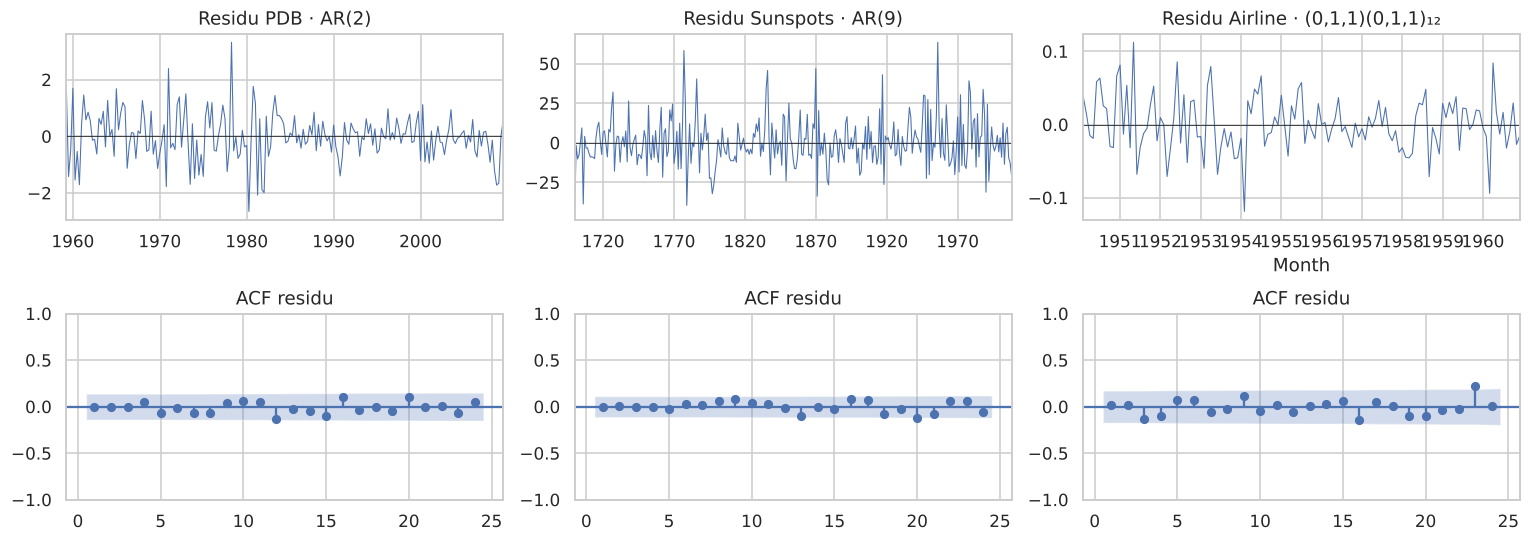

In [21]:
# Residu model terpilih: plot dan ACF
terpilih = {'PDB · AR(2)': (fit_gdp['AR(2)'], 0), 'Sunspots · AR(9)': (fit_sun['AR(9)'], 0), 'Airline · (0,1,1)(0,1,1)₁₂': (fit_air['(0,1,1)(0,1,1)₁₂'], 13)}
fig, axs = plt.subplots(2, 3, figsize=(14, 5))
for j, (nama, (res, buang)) in enumerate(terpilih.items()):
    e = res.resid.iloc[buang:]
    e.plot(ax=axs[0, j], lw=.7, title=f'Residu {nama}'); axs[0, j].axhline(0, color='k', lw=.5)
    plot_acf(e, lags=24, ax=axs[1, j], zero=False, title='ACF residu')
plt.tight_layout(); plt.show()

> - **Sunspots AR(2)** gagal uji Ljung–Box: model sederhana menangkap siklus, tetapi masih ada autokorelasi tersisa. **AR(9)** lolos —
>   konsisten dengan pilihan AICc.
> - Pada **PDB** dan **Airline**, model terpilih menghasilkan residu tanpa autokorelasi signifikan; ACF residu berada di dalam pita.
> - Urutan keputusan yang dianjurkan: (1) buang model yang tidak konvergen atau tidak stasioner/invertibel; (2) buang model yang residunya
>   bukan white noise; (3) di antara yang tersisa, pilih AICc/BIC terkecil — dan bila selisihnya < 2, pilih yang **paling sederhana**.

### 7.5 Apakah identifikasi berhasil? Uji pada orde yang diketahui

Kita membangkitkan 40 deret dari masing-masing tiga proses ARMA yang **diketahui** (n = 150) dan mencatat seberapa sering AIC dan BIC memilih orde yang benar.

In [22]:
benar = {'ARMA(1,1)': ((1, 0, 1), [1, -0.6], [1, 0.4]), 'AR(2)': ((2, 0, 0), [1, -0.5, 0.3], [1]), 'MA(1)': ((0, 0, 1), [1], [1, 0.6])}
rekap = []
for nama, (orde, ar, ma) in benar.items():
    tepat = {'AIC': 0, 'BIC': 0}; R = 40
    for i in range(R):
        y = ArmaProcess(ar, ma).generate_sample(150, distrvs=np.random.default_rng(100 + i).standard_normal)
        t_ = cari_orde(y, p_maks=2, q_maks=2)
        tepat['AIC'] += t_.AIC.idxmin() == orde; tepat['BIC'] += t_.BIC.idxmin() == orde
    rekap.append({'proses sebenarnya': nama, 'AIC tepat': tepat['AIC'] / R, 'BIC tepat': tepat['BIC'] / R})
pd.DataFrame(rekap).set_index('proses sebenarnya')

,AIC tepat,BIC tepat
proses sebenarnya,,
"ARMA(1,1)",0.425,0.525
AR(2),0.450,0.475
MA(1),0.700,0.975


> Bahkan ketika data benar-benar berasal dari ARMA dengan orde yang diketahui, kriteria informasi **tidak selalu** menemukan orde yang tepat.
> BIC lebih sering tepat untuk proses sederhana karena hukumannya lebih berat; AIC cenderung memilih model sedikit lebih besar. Pada data nyata
> tidak ada "orde sebenarnya" — tujuan kita adalah model yang **cukup baik** untuk meramal dengan residu yang menyerupai white noise.

---
## 8. 🧠 Konsep Pemrograman — Pencarian Orde yang Tangguh

| Konsep | Di notebook ini |
|---|---|
| **`itertools.product`** | Membangkitkan semua kombinasi (p, q) atau (p, q, P, Q) tanpa loop bersarang yang dalam |
| **Penanganan exception** | Estimasi dapat gagal (matriks singular, parameter tak stasioner) → dicatat sebagai "gagal", loop tetap jalan |
| **Menangkap peringatan** | `warnings.catch_warnings(record=True)` mendeteksi estimasi yang **tidak konvergen** — hasilnya tidak boleh dipercaya |
| **Ledakan kombinatorial** | (p_maks+1)(q_maks+1) model; SARIMA dengan 4 orde ≤ 2 = 81 model × beberapa detik |
| **Fungsi yang dapat dipakai ulang** | `uji_stasioner`, `tentukan_d`, `estimasi`, `periksa_akar`, `cari_orde`, `cari_sarima` dipakai lagi di P7, P9, P15 dan Tugas 2 |

In [23]:
# Ledakan kombinatorial: perkirakan waktu sebelum menjalankan pencarian besar
t0 = time.time(); SARIMAX(ly, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False); per_model = time.time() - t0
for maks in [1, 2, 3]:
    n_model = (maks + 1) ** 4
    print(f'p,q,P,Q ≤ {maks}: {n_model:>3} model ≈ {n_model * per_model:6.1f} dtk')
print('-> pencarian bertahap (perbaiki bagian musiman dulu, lalu bagian biasa) atau stepwise ala auto.arima jauh lebih hemat.')

p,q,P,Q ≤ 1:  16 model ≈   13.9 dtk
p,q,P,Q ≤ 2:  81 model ≈   70.1 dtk
p,q,P,Q ≤ 3: 256 model ≈  221.6 dtk
-> pencarian bertahap (perbaiki bagian musiman dulu, lalu bagian biasa) atau stepwise ala auto.arima jauh lebih hemat.


---
## 9. Latihan

### LATIHAN 1 — Tugas 2, langkah 2
Terapkan ketujuh langkah pada data Tugas Anda: visualisasikan, uji stasioneritas, tentukan d (dan D), baca ACF/PACF, susun 3–4 kandidat,
estimasi, lalu bandingkan dengan AICc/BIC dan uji Ljung–Box. Apakah kandidat dari ACF/PACF sama dengan pilihan `cari_orde`/`cari_sarima`?

In [24]:
# TODO

### LATIHAN 2 — Stepwise
Tulis `cari_stepwise(y, mulai=(1,0,1))` yang dimulai dari satu orde, mencoba tetangga (p±1, q±1), pindah ke tetangga dengan AICc
terkecil, dan berhenti bila tidak ada perbaikan. Bandingkan jumlah model yang diestimasi dengan pencarian penuh.

In [25]:
# TODO

### LATIHAN 3 — Musiman tanpa log
Ulangi Langkah 1–7 untuk Airline **tanpa** log. Apakah orde terbaik berubah? Bagaimana residunya? Mengapa transformasi log penting di sini?

In [26]:
# TODO

---
## 10. Ringkasan Pertemuan 6

1. **Visualisasi** — kenali tren, musiman, siklus, dan variansi yang berubah; transformasi log bila variansi membesar seiring level.
2. **Stasioneritas** — gabungkan statistik bergulir dengan uji ADF (H₀: akar unit) dan KPSS (H₀: stasioner).
3. **Differencing** — pilih d (dan D) terkecil; untuk data musiman lakukan differencing musiman, bukan differencing biasa kedua.
4. **ACF/PACF** — dibaca pada deret yang sudah stasioner; perhatikan pola terpotong vs meluruh dan lag musiman m, 2m, 3m.
5. **Kandidat orde** — PACF terpotong → AR(p); ACF terpotong → MA(q); keduanya meluruh → ARMA; susun beberapa kandidat.
6. **Estimasi** — periksa signifikansi, konvergensi, serta akar AR/MA di luar lingkaran satuan (stasioner & invertibel).
7. **Bandingkan & evaluasi** — AICc/BIC pada d dan D yang sama, residu white noise (Ljung–Box), dan pilih yang paling sederhana bila setara.

### Tugas mandiri (PT & BM)
Baca Hyndman & Athanasopoulos (2021) Bab 9.1–9.9. **Tugas 2 dimulai minggu depan.**

**Pertemuan berikutnya:** `P07_Pembangunan_Model_ARIMA_SARIMA.ipynb`

---
## Logbook Praktikum — Pertemuan 6

Salin sel di bawah, isi, lalu unggah bersama notebook ke LMS/Virtual Lab (aktivitas PT & BM sesuai RPS).

In [27]:
logbook = {
    'Nama / NIM'                          : 'TODO',
    'Pertemuan'                           : 6,
    'Tanggal praktikum'                   : 'TODO',
    'Tiga temuan terpenting (dengan angka)': ['TODO', 'TODO', 'TODO'],
    'Galat yang ditemui & cara mengatasi' : 'TODO',
    'Latihan yang diselesaikan'           : 'TODO',
    'Pertanyaan untuk pertemuan berikutnya': 'TODO',
}
for k, v in logbook.items():
    print(f'{k:<38}: {v}')

Nama / NIM                            : TODO
Pertemuan                             : 6
Tanggal praktikum                     : TODO
Tiga temuan terpenting (dengan angka) : ['TODO', 'TODO', 'TODO']
Galat yang ditemui & cara mengatasi   : TODO
Latihan yang diselesaikan             : TODO
Pertanyaan untuk pertemuan berikutnya : TODO
